## 📌 **Extracción**

In [12]:
import pandas as pd
import numpy as np
import json

In [13]:

url = "https://raw.githubusercontent.com/ingridcristh/challenge2-data-science-LATAM/refs/heads/main/TelecomX_Data.json"
df = pd.read_json(url)
df = pd.json_normalize(
    df.to_dict(orient="records"),
    sep="_"
)
df.head()

,customerID,Churn,customer_gender,customer_SeniorCitizen,customer_Partner,customer_Dependents,customer_tenure,phone_PhoneService,phone_MultipleLines,internet_InternetService,...,internet_OnlineBackup,internet_DeviceProtection,internet_TechSupport,internet_StreamingTV,internet_StreamingMovies,account_Contract,account_PaperlessBilling,account_PaymentMethod,account_Charges_Monthly,account_Charges_Total
0,0002-ORFBO,No,Female,0,Yes,Yes,9,Yes,No,DSL,...,Yes,No,Yes,Yes,No,One year,Yes,Mailed check,65.6,593.3
1,0003-MKNFE,No,Male,0,No,No,9,Yes,Yes,DSL,...,No,No,No,No,Yes,Month-to-month,No,Mailed check,59.9,542.4
2,0004-TLHLJ,Yes,Male,0,No,No,4,Yes,No,Fiber optic,...,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,73.9,280.85
3,0011-IGKFF,Yes,Male,1,Yes,No,13,Yes,No,Fiber optic,...,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,98.0,1237.85
4,0013-EXCHZ,Yes,Female,1,Yes,No,3,Yes,No,Fiber optic,...,No,No,Yes,Yes,No,Month-to-month,Yes,Mailed check,83.9,267.4


In [16]:
df = df.rename(columns={
    "customer_gender": "gender",
    "customerID": "customer_ID",
    "Churn": "churn",
    "multipleLines": "multiple_lines",
    "customer_SeniorCitizen": "senior_citizen",
    "customer_Partner":"partner",
    "customer_Dependents":"dependents",
    "customer_tenure":"tenure",
    "phone_PhoneService":"phone_service",
    "phone_MultipleLines":"multiple_lines",
    "internet_InternetService":"internet_service",
    "internet_OnlineSecurity":"online_security",
    "internet_OnlineBackup":"online_backup",
    "internet_DeviceProtection":"device_protection",
    "internet_TechSupport":"tech_support",
    "internet_StreamingTV":"streaming_TV",
    "internet_StreamingMovies":"streaming_movies",
    "account_Contract":"contract",
    "account_PaperlessBilling":"paperless_billing",
    "account_PaymentMethod":"payment_method",
    "account_Charges_Monthly":"charges_monthly",
    "account_Charges_Total":"charges_total"
})

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 0 to 7266
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_ID        7043 non-null   object 
 1   churn              7043 non-null   int64  
 2   gender             7043 non-null   object 
 3   senior_citizen     7043 non-null   int64  
 4   partner            7043 non-null   int64  
 5   dependents         7043 non-null   int64  
 6   tenure             7043 non-null   int64  
 7   phone_service      7043 non-null   int64  
 8   multiple_lines     7043 non-null   int64  
 9   internet_service   7043 non-null   object 
 10  online_security    7043 non-null   int64  
 11  online_backup      7043 non-null   object 
 12  device_protection  7043 non-null   int64  
 13  tech_support       7043 non-null   int64  
 14  streaming_TV       7043 non-null   int64  
 15  streaming_movies   7043 non-null   int64  
 16  contract           7043 non-n

##  **🔧Transformación**

In [18]:
df.dtypes

,0
customer_ID,object
churn,object
gender,object
senior_citizen,int64
partner,object
dependents,object
tenure,int64
phone_service,object
multiple_lines,object
internet_service,object


### **Comprobación de incoherencias en los datos**

In [19]:
print(df.isnull().sum())

customer_ID          0
churn                0
gender               0
senior_citizen       0
partner              0
dependents           0
tenure               0
phone_service        0
multiple_lines       0
internet_service     0
online_security      0
online_backup        0
device_protection    0
tech_support         0
streaming_TV         0
streaming_movies     0
contract             0
paperless_billing    0
payment_method       0
charges_monthly      0
charges_total        0
dtype: int64


In [20]:
pd.unique(df["customer_ID"])

array(['0002-ORFBO', '0003-MKNFE', '0004-TLHLJ', ..., '9992-UJOEL',
       '9993-LHIEB', '9995-HOTOH'], dtype=object)

In [21]:
pd.unique(df["churn"])
df['churn'] = df['churn'].replace('', np.nan)

# Ahora vuelve a revisar los nulos; esta vez sí aparecerán
print(df['churn'].isnull().sum())
# Eliminamos las filas donde Churn es nulo
df.dropna(subset=['churn'], inplace=True)
print(df['churn'].isnull().sum())
print(f"Nuevo tamaño del dataset: {df.shape}")

224
0
Nuevo tamaño del dataset: (7043, 21)


In [22]:
pd.unique(df["gender"])
pd.unique(df["senior_citizen"])
pd.unique(df["dependents"])
pd.unique(df["tenure"])
#print(df["tenure"].isnull().sum())

array([ 9,  4, 13,  3, 71, 63,  7, 65, 54, 72,  5, 56, 34,  1, 45, 50, 23,
       55, 26, 69, 37, 49, 66, 67, 20, 43, 59, 12, 27,  2, 25, 29, 14, 35,
       64, 39, 40, 11,  6, 30, 70, 57, 58, 16, 32, 33, 10, 21, 61, 15, 44,
       22, 24, 19, 47, 62, 46, 52,  8, 60, 48, 28, 41, 53, 68, 31, 36, 17,
       18, 51, 38, 42,  0])

In [23]:
cantidad_cero = (df['tenure'] == 0).sum()
print(f"Cantidad de clientes con tenure 0: {cantidad_cero}")

Cantidad de clientes con tenure 0: 11


In [24]:
pd.unique(df["multiple_lines"])
df['multiple_lines'] = df['multiple_lines'].replace('No phone service', 'No')
pd.unique(df["multiple_lines"])

array(['No', 'Yes'], dtype=object)

In [25]:
pd.unique(df["phone_service"])

array(['Yes', 'No'], dtype=object)

In [26]:
pd.unique(df["online_security"])
df['online_security'] = df['online_security'].replace('No internet service', 'No')
pd.unique(df["online_security"])



array(['No', 'Yes'], dtype=object)

In [59]:
pd.unique(df["internet_service"])

array(['DSL', 'Fiber optic', 0], dtype=object)

In [27]:
pd.unique(df["device_protection"])
df['device_protection'] = df['device_protection'].replace('No internet service', 'No')
pd.unique(df["device_protection"])



array(['No', 'Yes'], dtype=object)

In [28]:
pd.unique(df["tech_support"])
df['tech_support'] = df['tech_support'].replace('No internet service', 'No')
pd.unique(df["tech_support"])


pd.unique(df["streaming_TV"])
df['streaming_TV'] = df['streaming_TV'].replace('No internet service', 'No')



pd.unique(df["streaming_movies"])
df['streaming_movies'] = df['streaming_movies'].replace('No internet service', 'No')



pd.unique(df["contract"])
pd.unique(df["paperless_billing"])
pd.unique(df["payment_method"])
pd.unique(df["charges_monthly"])
pd.unique(df["charges_total"])

array(['593.3', '542.4', '280.85', ..., '742.9', '4627.65', '3707.6'],
      dtype=object)

In [29]:
print(df["charges_total"].isnull().sum())

0


In [40]:
df["charges_total"].unique()

array(['593.3', '542.4', '280.85', ..., '742.9', '4627.65', '3707.6'],
      dtype=object)

In [30]:
print(df["customer_ID"].isnull().sum())

0


In [44]:
#convirtiendo a float
df['charges_total'] = pd.to_numeric(df['charges_total'], errors='coerce')

### **Columna de cuentas diarias (Opcional)**

In [31]:
df["cuentas_diarias"] = df["charges_monthly"] / 30

df[["cuentas_diarias", "charges_monthly"]].head()

,cuentas_diarias,charges_monthly
0,2.186667,65.6
1,1.996667,59.9
2,2.463333,73.9
3,3.266667,98.0
4,2.796667,83.9


### **Estandarización y transformación de datos (opcional)**

In [35]:
# Definimos el mapa de transformación
mapeo = {'Yes': 1, 'No': 0}

# Aplicamos el cambio a todo el dataset
# Aquellos valores que no coincidan (como números o nombres) se mantendrán igual
df = df.replace(mapeo)

# Verificación rápida
print(df[['gender', 'partner', 'churn', "streaming_movies", "streaming_TV", "tech_support", "device_protection", "online_security", "phone_service", "multiple_lines"]].head())

   gender  partner  churn  streaming_movies  streaming_TV  tech_support  \
0  Female        1      0                 0             1             1   
1    Male        0      0                 1             0             0   
2    Male        0      1                 0             0             0   
3    Male        1      1                 1             1             0   
4  Female        1      1                 0             1             1   

   device_protection  online_security  phone_service  multiple_lines  
0                  0                0              1               0  
1                  0                0              1               1  
2                  1                0              1               0  
3                  1                0              1               0  
4                  0                0              1               0  


## **📊 Carga y análisis**

### **Análisis Descriptivo**

In [42]:
df.describe()

,churn,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,online_security,device_protection,tech_support,streaming_TV,streaming_movies,paperless_billing,charges_monthly,charges_total,cuentas_diarias
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000
mean,0.265370,0.162147,0.483033,0.299588,32.371149,0.903166,0.421837,0.286668,0.343888,0.290217,0.384353,0.387903,0.592219,64.761692,2283.300441,2.158723
std,0.441561,0.368612,0.499748,0.458110,24.559481,0.295752,0.493888,0.452237,0.475038,0.453895,0.486477,0.487307,0.491457,30.090047,2266.771362,1.003002
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,18.800000,0.608333
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,35.500000,401.450000,1.183333
50%,0.000000,0.000000,0.000000,0.000000,29.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,70.350000,1397.475000,2.345000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.850000,3794.737500,2.995000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,118.750000,8684.800000,3.958333


### **Distribución de evasión**

En este paso, el objetivo es comprender cómo está distribuida la variable "churn" (evasión) entre los clientes. Utiliza gráficos para visualizar la proporción de clientes que permanecieron y los que se dieron de baja.

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
# df["churn"].head()

# clientes_baja = df[df["churn"] == 0].value_counts().sum()
# print(clientes_baja)

# clientes_continuan = df[df["churn"] == 1].value_counts().sum()
# print(clientes_continuan)

5163
1869


In [50]:
# Esto te da el conteo de 0s y 1s automáticamente
conteo_churn = df['churn'].value_counts()
print(conteo_churn)

# Si quieres ver porcentajes (proporción), agrega normalize=True
proporcion_churn = df['churn'].value_counts(normalize=True) * 100
print(proporcion_churn)

churn
0    5174
1    1869
Name: count, dtype: int64
churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


/tmp/ipython-input-2792524137.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Se retiró', 'Continúan'])


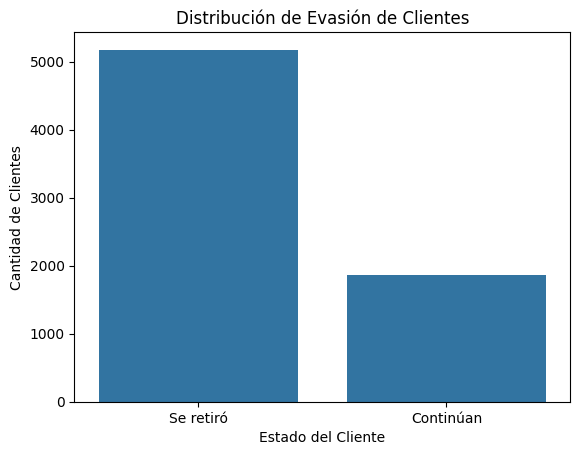

In [52]:

ax = sns.countplot(x='churn', data=df)

# Cambiar los nombres en el eje X (0 -> Se retiró, 1 -> Continúan)
ax.set_xticklabels(['Se retiró', 'Continúan'])

# Añadir títulos para que se vea profesional
plt.title('Distribución de Evasión de Clientes')
plt.xlabel('Estado del Cliente')
plt.ylabel('Cantidad de Clientes')

plt.show()

### **Recuento de evasión por variables categóricas**

In [58]:
df.groupby("churn")["gender"].value_counts()

churn  gender
0      Male      2625
       Female    2549
1      Female     939
       Male       930
Name: count, dtype: int64

/tmp/ipython-input-760867010.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(["Femenino", "Masculino"])
/tmp/ipython-input-760867010.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(["1 año", "Mes a mes", "2 años"])
/tmp/ipython-input-760867010.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(["DSL", "Fibra optica", "Sin internet"])
/tmp/ipython-input-760867010.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(["Correo", "Electrónico", "Tarjeta de crédito", "Banca"])


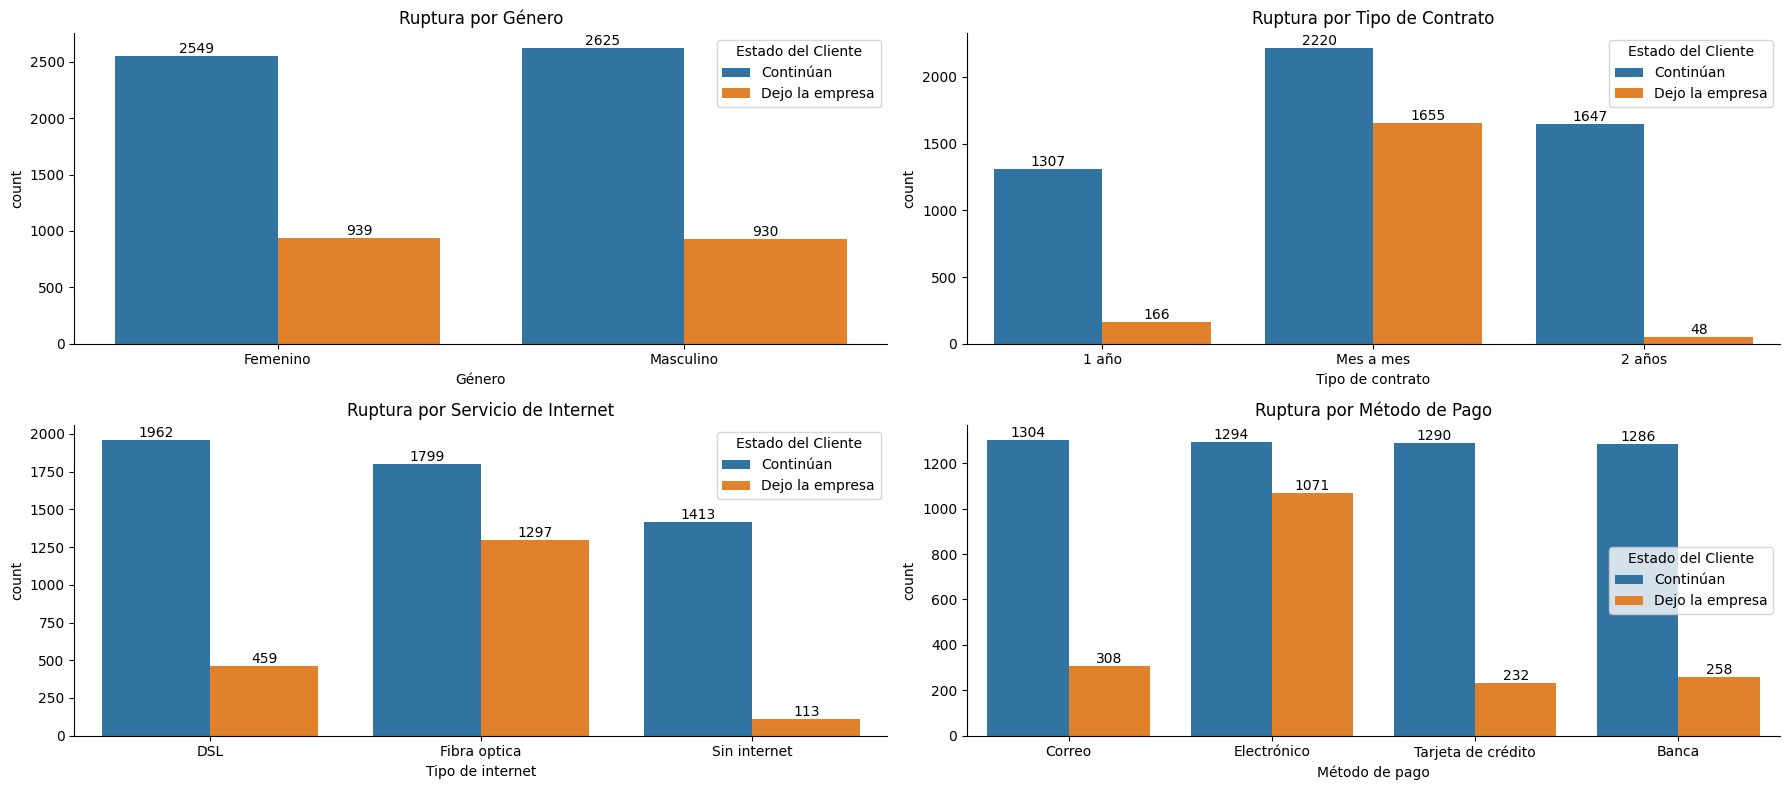

In [96]:
# Definimos una cuadrícula de 2 filas y 2 columnas
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 8))

# --- GRÁFICO 1: GÉNERO ---
sns.countplot(x='gender', hue='churn', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Ruptura por Género')
axes[0, 0].set_xticklabels(["Femenino", "Masculino"])
axes[0, 0].set_xlabel("Género")
axes[0, 0].legend(title='Estado del Cliente', labels=['Continúan', 'Dejo la empresa'])
axes[0, 0].spines['top'].set_visible(False) # <--- BORRA EL BORDE SUPERIOR
axes[0, 0].spines['right'].set_visible(False) # <--- BORRA EL BORDE DERECHO
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container)

# --- GRÁFICO 2: CONTRATO ---
sns.countplot(x='contract', hue='churn', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Ruptura por Tipo de Contrato')
axes[0, 1].set_xticklabels(["1 año", "Mes a mes", "2 años"])
axes[0, 1].set_xlabel("Tipo de contrato")
axes[0, 1].legend(title='Estado del Cliente', labels=['Continúan', 'Dejo la empresa'])
axes[0, 1].spines['top'].set_visible(False) # <--- BORRA EL BORDE SUPERIOR
axes[0, 1].spines['right'].set_visible(False) # <--- BORRA EL BORDE DERECHO
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container)

# --- GRÁFICO 3: INTERNET ---
sns.countplot(x='internet_service', hue='churn', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Ruptura por Servicio de Internet')
axes[1, 0].set_xticklabels(["DSL", "Fibra optica", "Sin internet"])
axes[1, 0].set_xlabel("Tipo de internet")
axes[1, 0].legend(title='Estado del Cliente', labels=['Continúan', 'Dejo la empresa'])
axes[1, 0].spines['top'].set_visible(False) # <--- BORRA EL BORDE SUPERIOR
axes[1, 0].spines['right'].set_visible(False) # <--- BORRA EL BORDE DERECHO
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container)

# --- GRÁFICO 4: PAGO ---
sns.countplot(x='payment_method', hue='churn', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Ruptura por Método de Pago')
axes[1, 1].set_xticklabels(["Correo", "Electrónico", "Tarjeta de crédito", "Banca"])
axes[1, 1].set_xlabel("Método de pago")
axes[1, 1].legend(title='Estado del Cliente', labels=['Continúan', 'Dejo la empresa'])
axes[1, 1].spines['top'].set_visible(False) # <--- BORRA EL BORDE SUPERIOR
axes[1, 1].spines['right'].set_visible(False) # <--- BORRA EL BORDE DERECHO
for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container)

plt.tight_layout()
plt.show()

### **Conteo de evasión por variables numéricas**

/tmp/ipython-input-913058053.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churn', y='tenure', data=df, ax=axes[0], palette=['#1f77b4', '#ff7f0e'])
/tmp/ipython-input-913058053.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Continúan', 'Se retiró']) # 0=Azul, 1=Naranja
/tmp/ipython-input-913058053.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churn', y='charges_total', data=df, ax=axes[1], palette=['#1f77b4', '#ff7f0e'])
/tmp/ipython-input-913058053.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks()

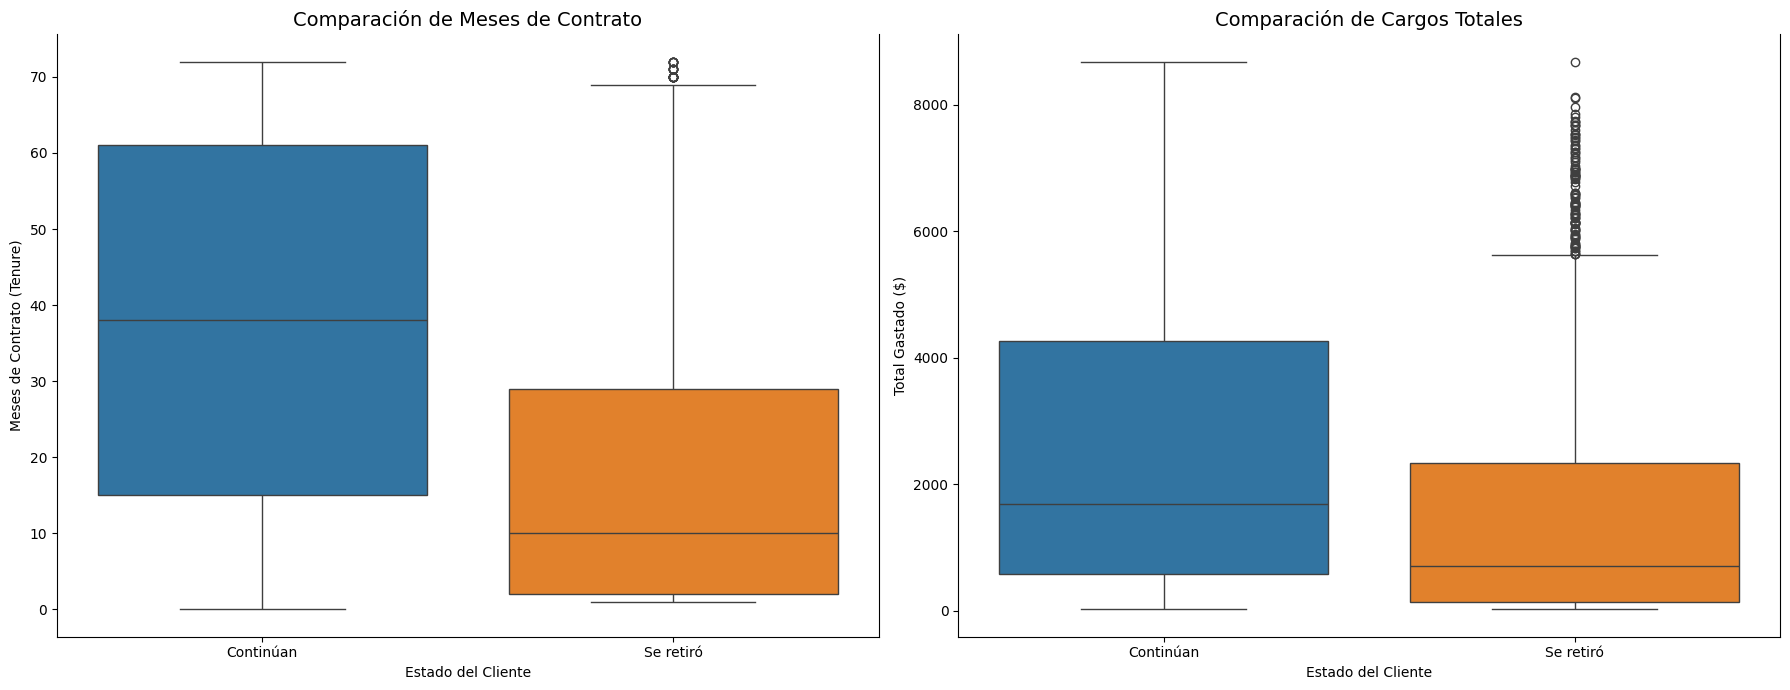

In [94]:
#charges_total

# Definimos la cuadrícula: 1 fila y 2 columnas
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# --- GRÁFICO 1: BOXPLOT DE ANTIGÜEDAD (TENURE) ---
sns.boxplot(x='churn', y='tenure', data=df, ax=axes[0], palette=['#1f77b4', '#ff7f0e'])
axes[0].set_title('Comparación de Meses de Contrato', fontsize=14)
axes[0].set_xlabel('Estado del Cliente')
axes[0].set_ylabel('Meses de Contrato (Tenure)')
axes[0].set_xticklabels(['Continúan', 'Se retiró']) # 0=Azul, 1=Naranja
axes[0].spines['top'].set_visible(False)

# --- GRÁFICO 2: BOXPLOT DE CARGOS TOTALES (CHARGES_TOTAL) ---
sns.boxplot(x='churn', y='charges_total', data=df, ax=axes[1], palette=['#1f77b4', '#ff7f0e'])
axes[1].set_title('Comparación de Cargos Totales', fontsize=14)
axes[1].set_xlabel('Estado del Cliente')
axes[1].set_ylabel('Total Gastado ($)')
axes[1].set_xticklabels(['Continúan', 'Se retiró'])
axes[1].spines['top'].set_visible(False)

plt.tight_layout()
plt.show()

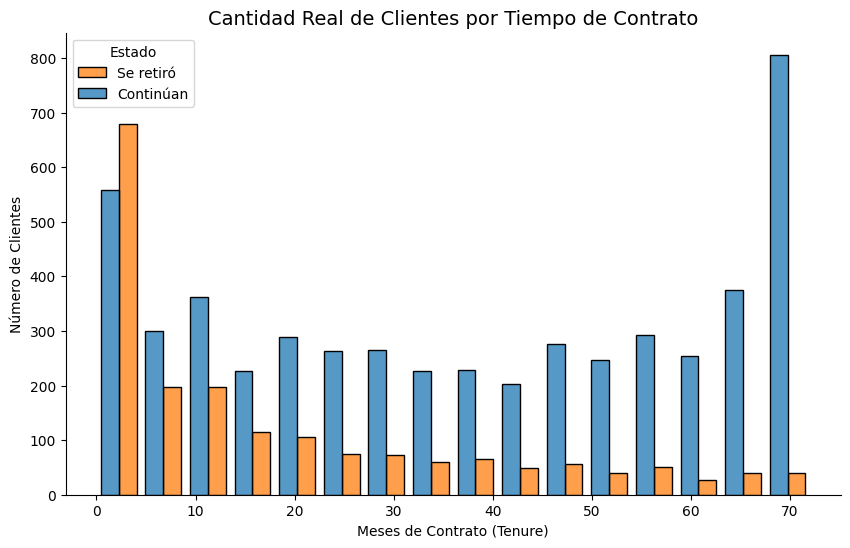

In [103]:
# --- GRÁFICO 1: TIEMPO DE CONTRATO (TENURE) ---
plt.figure(figsize=(10, 6))
# 'multiple="dodge"' separa las barras para que veas el conteo real de cada grupo
ax1 = sns.histplot(data=df, x='tenure', hue='churn', multiple="dodge", palette=['#1f77b4', '#ff7f0e'], shrink=0.8)

plt.title('Cantidad Real de Clientes por Tiempo de Contrato', fontsize=14)
plt.xlabel('Meses de Contrato (Tenure)')
plt.ylabel('Número de Clientes') # Eje Y con valores reales

# Limpieza estética (sin borde superior ni derecho)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.legend(title='Estado', labels=['Se retiró', 'Continúan'])
plt.show()

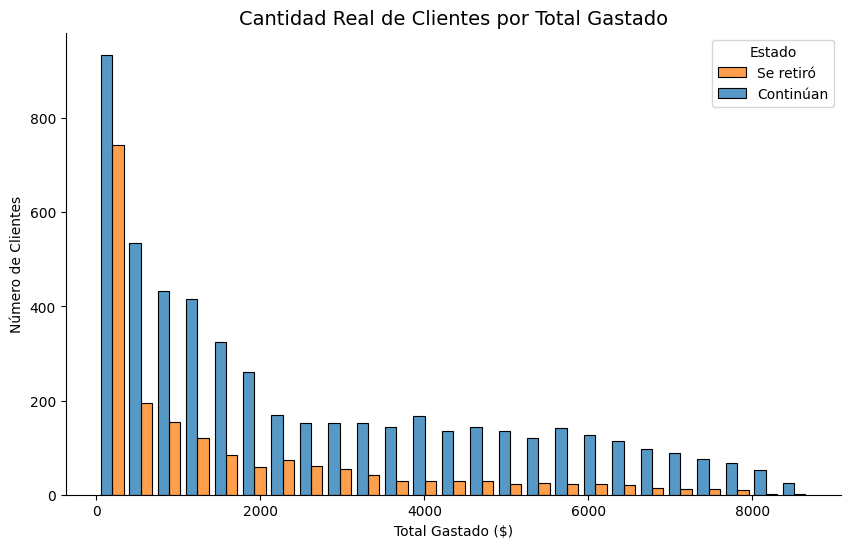

In [104]:
# --- GRÁFICO 2: CARGOS TOTALES (CHARGES_TOTAL) ---
plt.figure(figsize=(10, 6))
ax2 = sns.histplot(data=df, x='charges_total', hue='churn', multiple="dodge", palette=['#1f77b4', '#ff7f0e'], shrink=0.8)

plt.title('Cantidad Real de Clientes por Total Gastado', fontsize=14)
plt.xlabel('Total Gastado ($)')
plt.ylabel('Número de Clientes') # Eje Y con valores reales

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.legend(title='Estado', labels=['Se retiró', 'Continúan'])
plt.show()

## **📄Informe final**

###🔹 **Introducción:**
El objetivo de este análisis es identificar los factores críticos que influyen en la pérdida de clientes de la compañía. Comprender por qué los usuarios cancelan el servicio es fundamental para diseñar estrategias de retención efectivas y mejorar la sostenibilidad del modelo de negocio.

### 🔹 **Limpieza y Tratamiento de Datos:**
Para garantizar la precisión del análisis, se llevaron a cabo los siguientes pasos:
- **Carga de Datos:** Importación del conjunto de datos y verificación de tipos de variables (df.info()).
- **Preprocesamiento:** Conversión de la variable objetivo a un formato binario ($0$: Continúan, $1$: Se retiró) para facilitar el cálculo estadístico.
- **Traducción y Etiquetado:** Ajuste de nombres de columnas y categorías al español para asegurar un reporte claro y comprensible.


### 🔹 **Análisis Exploratorio de Datos:**

El análisis se dividió en dos grandes grupos de variables para identificar patrones de evasión.

A. Variables Categóricas

- Tipo de Contrato: Es el predictor más fuerte. Los clientes con contrato "Mes a mes" representan la gran mayoría de las fugas (1,655 retiros), mientras que los contratos a largo plazo (2 años) son los más estables con solo 48 retiros.

- Servicio de Internet: Los usuarios de Fibra óptica muestran una tasa de abandono significativamente mayor (1,297) que los de DSL o quienes no cuentan con el servicio.

- Método de Pago: El pago por Cheque electrónico concentra la mayor cantidad de evasiones (1,071).

B. Variables Numéricas
- Antigüedad (Tenure): Se confirma un punto crítico de fuga temprana. El riesgo de abandono es máximo durante los primeros 0 a 6 meses. Superar la barrera de los 20 meses reduce drásticamente la probabilidad de retiro.

- Cargos Totales: La evasión se concentra en niveles de gasto acumulado bajos, lo que refuerza la idea de que los clientes se retiran antes de consolidar un ciclo de vida largo con la empresa.

### 🔹 **Conclusiones e Insights:**
- La falta de compromiso contractual a largo plazo es el principal motor de la evasión.

- Existe una vulnerabilidad operativa en los servicios de Fibra Óptica y métodos de pago electrónicos que debe ser revisada.

- La relación con el cliente es más frágil durante el primer semestre de servicio.

### 🔹 **Recomendaciones:**
- Incentivos a la Permanencia: Crear campañas para migrar a clientes de contratos mensuales a planes anuales o bienales mediante descuentos progresivos.

- Acompañamiento Inicial: Implementar un plan de "Bienvenida" con soporte técnico prioritario durante los primeros 6 meses para asegurar que el cliente encuentre valor rápido en el servicio.

- Optimización de Servicios: Investigar las causas técnicas o de facturación detrás de la insatisfacción en usuarios de fibra óptica y cheques electrónicos.